In [47]:
# load the posts: one row per post, with the verdict from its flair
import pandas as pd

posts = pd.read_csv("https://raw.githubusercontent.com/macss-berkeley/compss-211a/main/data/week10_posts.csv")
posts.shape  # (785, 4)

(785, 4)

In [48]:
# the three example posts from the slides
examples = [69, 773, 175]
posts.loc[examples, ["title", "verdict"]]

,title,verdict
69,AITA for refusing to call my unborn nephew by ...,NTA
773,AITA for getting mad at my parents after they ...,NTA
175,AITA for not wanting my daughter to marry her ...,YTA


## TF-IDF

In [49]:
# make the TF-IDF table: one row per post, one column per word
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(stop_words="english", min_df=30)  # words in at least 30 posts
weights = pd.DataFrame(tfidf.fit_transform(posts["text"]).toarray(),
                       columns=tfidf.get_feature_names_out())
weights.shape  # (785, 350)

(785, 350)

In [50]:
# the weights of six words for the three example posts
weights.loc[examples, ["kid", "refused", "parents", "school", "daughter", "honestly"]].round(2)

,kid,refused,parents,school,daughter,honestly
69,0.58,0.3,0.00,0.00,0.00,0.00
773,0.00,0.0,0.41,0.26,0.00,0.00
175,0.00,0.0,0.00,0.00,0.55,0.19


In [51]:
# average the TF-IDF weights of the NTA posts, and of the YTA posts
by_verdict = pd.DataFrame({
    "NTA": weights[posts["verdict"] == "NTA"].mean(),
    "YTA": weights[posts["verdict"] == "YTA"].mean(),
})

# divide the YTA average by the NTA average: above 1 means the word is more YTA
by_verdict["ratio"] = by_verdict["YTA"] / by_verdict["NTA"]
by_verdict.sort_values("ratio")

,NTA,YTA,ratio
bedroom,0.011837,0.000000,0.000000
sick,0.010131,0.000000,0.000000
food,0.020744,0.002646,0.127533
cut,0.009594,0.001327,0.138284
sorry,0.011075,0.003077,0.277819
...,...,...,...
feels,0.006274,0.014867,2.369582
wife,0.033637,0.081434,2.420994
born,0.006178,0.014973,2.423568
looks,0.006095,0.015855,2.601405


<Axes: xlabel='average TF-IDF weight'>

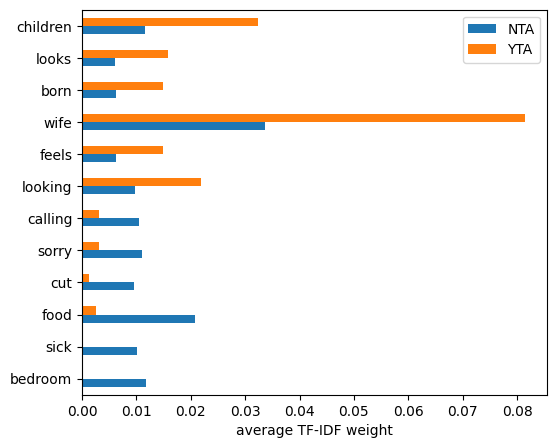

In [52]:
# plot the 6 most NTA-like and the 6 most YTA-like words
by_ratio = by_verdict.sort_values("ratio")
selected = pd.concat([by_ratio.head(6), by_ratio.tail(6)])
selected[["NTA", "YTA"]].plot.barh(figsize=(6, 5), xlabel="average TF-IDF weight", ylabel="")

## Embeddings

In [53]:
# turn every post into 384 numbers
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")  # downloads about 90 MB the first time
embeddings = model.encode(posts["text"].tolist(), normalize_embeddings=True)
embeddings.shape  # (785, 384)

(785, 384)

In [54]:
# the first 4 of the 384 numbers for the three example posts
pd.DataFrame(embeddings[examples, :4], index=examples).round(2)

,0,1,2,3
69,-0.01,-0.01,-0.06,0.05
773,-0.03,0.07,-0.01,0.02
175,0.00,0.06,-0.01,-0.01


In [55]:
# find the posts closest to a sentence
query = model.encode(["My roommate keeps eating my food."], normalize_embeddings=True)[0]
posts["similarity"] = embeddings @ query  # how close each post is to the sentence
posts.sort_values("similarity", ascending=False).head(4)[["similarity", "verdict", "title"]]

,similarity,verdict,title
306,0.557881,NTA,AITA for refusing to give up eating non halal ...
130,0.510880,NTA,AITA for locking my expensive pots and pans to...
442,0.509022,NTA,AITA for refusing to help roommate's girlfrien...
27,0.495358,NTA,AITA for ordering a meat dish while eating wit...


## An LLM label: does the poster admit fault?

Needs `GEMINI_API_KEY` in your `.env` file. 15 calls.

In [56]:
# connect to gemini with the key from your .env file
import os

from dotenv import load_dotenv
from google import genai

load_dotenv()
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [57]:
# ask gemini whether each example poster admits fault; the definition is the system instruction
from google.genai import types

definition = ("Label whether the poster admits that they did something wrong.\n"
              "yes: the poster says that something they did was wrong, unfair,\n"
              "or an overreaction, even in passing.\n"
              "no: the poster does not admit any fault. Give a reason of one sentence.")

for i in examples:  # 3 posts, 3 calls
    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=posts.loc[i, "text"],
        config=types.GenerateContentConfig(system_instruction=definition),
    )
    print(posts.loc[i, "title"])
    print(response.text)
    print()

AITA for refusing to call my unborn nephew by his name?
yes: The poster admits, even if defensively, to being called a "bitch" by their sister for refusing to use the name.

AITA for getting mad at my parents after they didn’t tell me about my autism diagnosis until 12 years after I was diagnosed?
yes

AITA for not wanting my daughter to marry her cousin?
no: The poster stands by their decision to withhold wedding funding and expresses no regret over their actions.



In [58]:
# the same question, but gemini must answer with a label (yes or no) and a reason
import json

config = types.GenerateContentConfig(
    system_instruction=definition,
    response_mime_type="application/json",  # answer in JSON
    response_schema={                       # with exactly these two fields
        "type": "object",
        "properties": {
            "label": {"type": "string", "enum": ["yes", "no"]},  # only yes or no allowed
            "reason": {"type": "string"},
        },
        "required": ["label", "reason"],
    },
)

for i in examples:  # 3 calls
    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=posts.loc[i, "text"],
        config=config,
    )
    answer = json.loads(response.text)  # turn the JSON text into a dictionary
    print(posts.loc[i, "title"])
    print(response.text)                # the answer as gemini sent it
    print("label:", answer["label"])    # one field from the dictionary
    print()

AITA for refusing to call my unborn nephew by his name?
{
  "label": "no",
  "reason": "The poster does not admit any fault and maintains that their sister's name choice is entirely wrong."
}
label: no

AITA for getting mad at my parents after they didn’t tell me about my autism diagnosis until 12 years after I was diagnosed?
{
  "label": "no",
  "reason": "The poster does not acknowledge that getting mad and yelling at her parents was wrong, but rather justifies her anger and questions if she is the asshole."
}
label: no

AITA for not wanting my daughter to marry her cousin?
{
  "label": "no",
  "reason": "The poster maintains that they are justified in refusing to pay for the wedding and cutting off support."
}
label: no



## Agreement between two labelers

In [61]:
# agreement and kappa for two labelers on the same 30 posts
from sklearn.metrics import cohen_kappa_score

labels_a = ["yes"] * 4 + ["no"] * 26                          # you: yes for posts 1-4
labels_b = ["yes"] * 3 + ["no"] + ["yes"] * 2 + ["no"] * 24   # a classmate: yes for posts 1-3 and 5-6
agreement = (pd.Series(labels_a) == pd.Series(labels_b)).mean()
agreement, cohen_kappa_score(labels_a, labels_b)  # (0.9, 0.61)

(np.float64(0.9), np.float64(0.6086956521739131))